In [15]:
import os
import matplotlib.pyplot as plt
import numpy as np
import scipy.io as sio
import datetime
import pytz
import seaborn as sns
sns.set_theme(style="whitegrid")

In [18]:
results_dir = '/home/ishani/LeoPNT/starlink_ofdm/Starloc/results/final'
res_dirs = [d for d in os.listdir(results_dir) if os.path.isdir(os.path.join(results_dir, d))]
res_dirs = [d for d in res_dirs if '5Feb' not in d]
res_dict = {}
for dir in res_dirs:
    print(dir)
    loc_file = os.path.join(results_dir, dir, 'loc.txt')
    baseline_file = os.path.join(results_dir, dir, 'baseline.txt')
    with open(loc_file, 'r') as f:
        loc_data = f.read().splitlines()
    with open(baseline_file, 'r') as f:
        baseline_data = f.read().splitlines()
    # for line in loc_data:
    #     print(line)
    gt = np.array(loc_data[2].split(' '), dtype=np.float64)
    coarse_loc = np.array(loc_data[4].split(' '), dtype=np.float64)
    coarse_loc_err = np.array(loc_data[6].split(' '), dtype=np.float64)
    total_sats, train_sats = np.array(loc_data[8].split(' '), dtype=np.int32)
    test_sats = total_sats - train_sats
    phase_err_overall = np.array(loc_data[10].split(' ')[-1], dtype=np.float64)
    x_err = np.array(loc_data[10].split(' ')[0], dtype=np.float64)
    y_err = np.array(loc_data[10].split(' ')[1], dtype=np.float64)
    # calculate coordinate from error with respect to gt
    latitude, longitude = gt
    r_earth = 6378.1 #km
    dx = x_err/1000
    dy = y_err/1000
    new_latitude  = latitude  + (dy / r_earth) * (180 / np.pi)
    new_longitude = longitude + (dx / r_earth) * (180 / np.pi) / np.cos(latitude * np.pi/180)
    
    dopp_err_overall = np.array(loc_data[12].split(' ')[-1], dtype=np.float64)
    avg_err_overall = np.array(loc_data[14].split(' ')[-1], dtype=np.float64)
    phase_err_persat_lines, dopp_err_persat_lines, avg_err_persat_lines = loc_data[16:16+test_sats], loc_data[16+test_sats+1:16+2*test_sats+1], loc_data[16+2*test_sats+2:16+3*test_sats+2]
    phase_err_persat = np.array([float(err.split(' ')[-1]) for err in phase_err_persat_lines])
    dopp_err_persat = np.array([float(err.split(' ')[-1]) for err in dopp_err_persat_lines])
    avg_err_persat = np.array([float(err.split(' ')[-1]) for err in avg_err_persat_lines])
    #append to dictionary
    res_dict[dir] = {}
    res_dict[dir]['gt'] = gt
    res_dict[dir]['loc_coords'] = [new_latitude, new_longitude]
    res_dict[dir]['coarse_loc'] = coarse_loc
    res_dict[dir]['coarse_loc_err'] = coarse_loc_err
    res_dict[dir]['total_sats'] = total_sats
    res_dict[dir]['train_sats'] = train_sats
    res_dict[dir]['test_sats'] = test_sats
    res_dict[dir]['phase_err_overall'] = phase_err_overall
    res_dict[dir]['dopp_err_overall'] = dopp_err_overall
    res_dict[dir]['avg_err_overall'] = avg_err_overall
    res_dict[dir]['phase_err_persat'] = phase_err_persat
    res_dict[dir]['dopp_err_persat'] = dopp_err_persat
    res_dict[dir]['avg_err_persat'] = avg_err_persat

    sat_ids = sio.loadmat(os.path.join(results_dir, dir, 'phase_comp.mat'))['id_dict']
    sat_ids = [id[0] for id in sat_ids[0]]
    
    tle_path = os.path.join(results_dir, dir, 'Starlink.tle')
    tle_dict = {}
    with open(tle_path, 'r') as f:
        tle_data = f.read().splitlines()
        for idx,line in enumerate(tle_data):
            if 'STARLINK' in line:
                sat_id = line.strip()
                l = tle_data[idx+1].split(' ')
                l = [x for x in l if x]
                tle_dict[sat_id] = l[3]
    res_dict[dir]['sat_id_epoch'] = []
    cap_time = sio.loadmat(os.path.join(results_dir, dir, 'info.mat'))['start_time'][0][0]
    for id in sat_ids[train_sats:]:
        epoch = tle_dict[id]
        year = int('20' + epoch[:2])
        day = int(epoch[2:5])
        # print(day)
        time = float(epoch[5:])
        hour = int(time*24)
        min = int((time*24 - hour)*60)
        sec = int(((time*24 - hour)*60 - min)*60)
        # print(id, f'{year} {day} {hour} {min} {sec}', dir)
        # convert to UTC timestamp
        ts = datetime.datetime(year, 1, 1, 0, 0, 0, 0, pytz.UTC) + datetime.timedelta(day - 1, hours=hour, minutes=min, seconds=sec)
        ts = ts.timestamp()
        # print(ts, cap_time, ((cap_time-ts)/60)/60)
        res_dict[dir]['sat_id_epoch'].append([id, ts, cap_time, ((cap_time-ts)/60)/60])

    dopp_baseline_overall = baseline_data[3].split(' ')[-1]
    # persat baseline
    dopp_baseline_persat_lines = baseline_data[7::2]
    dopp_baseline_persat = np.array([err.split(' ')[-1] for err in dopp_baseline_persat_lines], dtype=np.float64)
    res_dict[dir]['dopp_baseline_overall'] = dopp_baseline_overall
    res_dict[dir]['dopp_baseline_persat'] = dopp_baseline_persat[train_sats:]
    print(dopp_baseline_overall, phase_err_overall)


6Mar2024_04_19
2800.1202664062807 1965.5886648852197
13Mar2024_03_59
2576.484019266021 1782.3264171827332
13Mar2024_03_17
2529.385138837492 2036.2612652617888
12Mar2024_23_35
5086.917296204977 2189.2483327429113
13Mar2024_02_20
2549.115431080448 2663.790609185643
13Mar2024_00_54
4576.775371232964 714.2045428920565
13Mar2024_00_35
2653.12478092064 607.1882398791253
12Mar2024_23_17
3459.6135453023962 2839.9741006924196
13Mar2024_05_37
2185.073068362668 1423.0957043724923
20Feb2024_23_19


5661.1894583294215 2243.9310112327744
6Mar2024_03_51
3926.298029520563 3728.7651174048547


### Plot CDF for overall error

avg_phase_err 2017.670364157456
avg_dopp_err 3163.6742715225187
avg_avg_err 1918.4462822472667


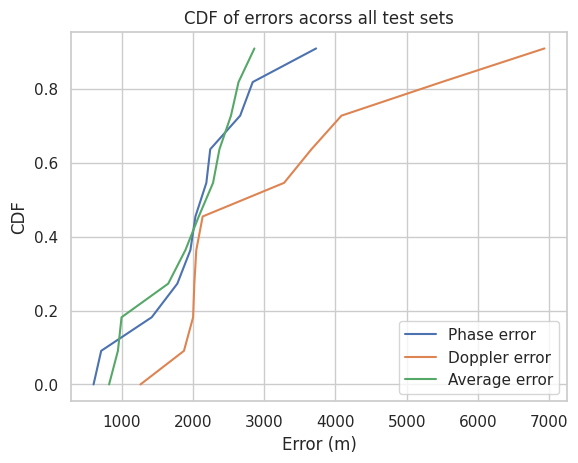

In [19]:
overall_phase_err = [res_dict[dir]['phase_err_overall'] for dir in res_dirs]
overall_dopp_err = [res_dict[dir]['dopp_err_overall'] for dir in res_dirs]
overall_avg_err = [res_dict[dir]['avg_err_overall'] for dir in res_dirs]
avg_phase_err = np.mean(overall_phase_err)
avg_dopp_err = np.mean(overall_dopp_err)
avg_avg_err = np.mean(overall_avg_err)
print('avg_phase_err', avg_phase_err)
print('avg_dopp_err', avg_dopp_err)
print('avg_avg_err', avg_avg_err)

# plot CDF of all errors
overall_phase_err = np.sort(overall_phase_err)
overall_dopp_err = np.sort(overall_dopp_err)
overall_avg_err = np.sort(overall_avg_err)
yvals = np.arange(len(overall_phase_err))/float(len(overall_phase_err))
plt.plot(overall_phase_err, yvals, label='Phase error')
plt.plot(overall_dopp_err, yvals, label='Doppler error')
plt.plot(overall_avg_err, yvals, label='Average error')
plt.legend(loc='lower right')
plt.xlabel('Error (m)')
plt.ylabel('CDF')
plt.title('CDF of errors acorss all test sets')
plt.show()

### Plot CDF with errors from each satellite

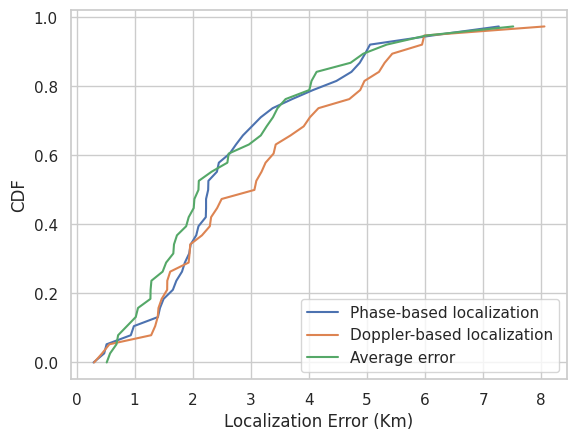

In [20]:
persat_phase_err = [res_dict[dir]['phase_err_persat'] for dir in res_dirs]
persat_dopp_err = [res_dict[dir]['dopp_err_persat'] for dir in res_dirs]
persat_avg_err = [res_dict[dir]['avg_err_persat'] for dir in res_dirs]
# make array flat
persat_phase_err = np.concatenate(persat_phase_err)
persat_dopp_err = np.concatenate(persat_dopp_err)
persat_avg_err = np.concatenate(persat_avg_err)

# plot CDF of errors per satellite
persat_phase_err = np.sort(persat_phase_err)
persat_dopp_err = np.sort(persat_dopp_err)
persat_avg_err = np.sort(persat_avg_err)
yvals = np.arange(len(persat_phase_err))/float(len(persat_phase_err))
plt.plot(persat_phase_err/1000, yvals, label='Phase-based localization')
plt.plot(persat_dopp_err/1000, yvals, label='Doppler-based localization')
plt.plot(persat_avg_err/1000, yvals, label='Average error')
# plt.vlines(avg_phase_err/1000, 0, 0.5, colors='g', linestyles='dashed')
# plt.hlines(0.5, 0, avg_phase_err/1000, colors='g', linestyles='dashed')
plt.legend(loc='lower right')
plt.xlabel('Localization Error (Km)', fontsize=12)
plt.ylabel('CDF', fontsize=12)
# plt.grid()
# plt.title('CDF of errors per satellite')
# plt.show()
#save with high DPI
plt.savefig('persat_cdf.pdf')


Mean: 20267.25688598088 Median: 14648.058371261337 Std: 17450.591759068066
Mean: 2680.66326235508 Median: 2248.3560597352516 Std: 1554.9925541163857


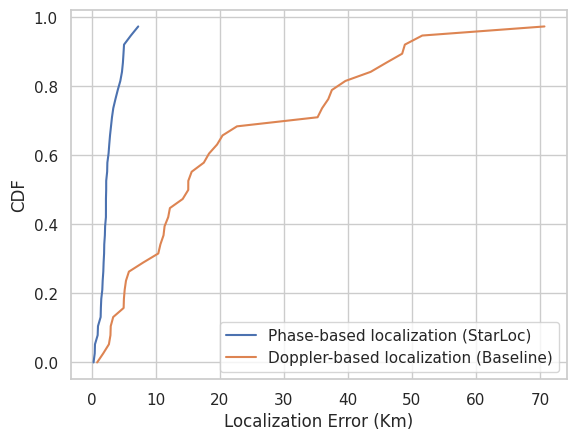

In [22]:
persat_phase_err = [res_dict[dir]['phase_err_persat'] for dir in res_dirs]
persat_dopp_err = [res_dict[dir]['dopp_err_persat'] for dir in res_dirs]
persat_avg_err = [res_dict[dir]['avg_err_persat'] for dir in res_dirs]
persat_dopp_baseline_err = [res_dict[dir]['dopp_baseline_persat'] for dir in res_dirs]
# make array flat
persat_phase_err = np.concatenate(persat_phase_err)
persat_dopp_err = np.concatenate(persat_dopp_err)
persat_avg_err = np.concatenate(persat_avg_err)
persat_dopp_baseline_err = np.concatenate(persat_dopp_baseline_err)
# plot CDF of errors per satellite
persat_phase_err = np.sort(persat_phase_err)
persat_dopp_err = np.sort(persat_dopp_err)
persat_avg_err = np.sort(persat_avg_err)
persat_dopp_baseline_err = np.sort(persat_dopp_baseline_err)
print("Mean:", np.mean(persat_dopp_baseline_err), "Median:", np.median(persat_dopp_baseline_err), "Std:", np.std(persat_dopp_baseline_err))
print("Mean:", np.mean(persat_phase_err), "Median:", np.median(persat_phase_err), "Std:", np.std(persat_phase_err))
yvals = np.arange(len(persat_phase_err))/float(len(persat_phase_err))
plt.plot(persat_phase_err/1000, yvals, label='Phase-based localization (StarLoc)')
plt.plot(persat_dopp_baseline_err/1000, yvals, label='Doppler-based localization (Baseline)')
# plt.plot(persat_dopp_err/1000, yvals, label='Doppler-based localization')
# plt.plot(persat_avg_err/1000, yvals, label='Average error')
# plt.vlines(avg_phase_err/1000, 0, 0.5, colors='g', linestyles='dashed')
# plt.hlines(0.5, 0, avg_phase_err/1000, colors='g', linestyles='dashed')
plt.legend(loc='lower right')
plt.xlabel('Localization Error (Km)', fontsize=12)
plt.ylabel('CDF', fontsize=12)
# plt.grid()
# plt.title('CDF of errors per satellite')
# plt.show()
#save with high DPI
plt.savefig('persat_cdf.pdf')


### Correlation between phase and doppler errors

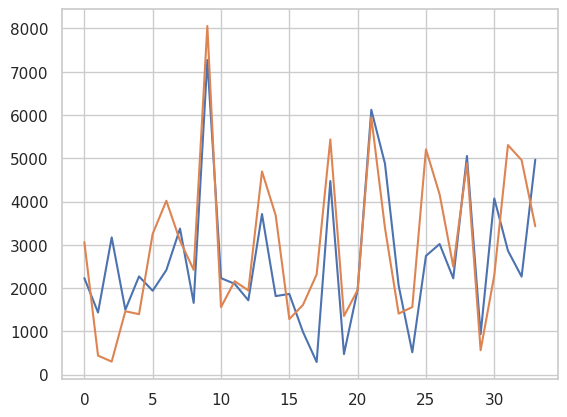

In [24]:
persat_phase_err = [res_dict[dir]['phase_err_persat'] for dir in res_dirs]
persat_dopp_err = [res_dict[dir]['dopp_err_persat'] for dir in res_dirs]
persat_avg_err = [res_dict[dir]['avg_err_persat'] for dir in res_dirs]
# make array flat
persat_phase_err = np.concatenate(persat_phase_err)
persat_dopp_err = np.concatenate(persat_dopp_err)
persat_avg_err = np.concatenate(persat_avg_err)
# get the sat_id_epoch for each satellite
staleness_persat = []
for dir in res_dirs:
    staleness_persat.append([x[3] for x in res_dict[dir]['sat_id_epoch']])
staleness_persat = np.concatenate(staleness_persat)

plt.figure()
plt.plot(persat_phase_err)
plt.plot(persat_dopp_err)


### Resolution vs Ambiguity with increase in antenna spacing 

[ 2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25
 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49]
k [-1  0  1]
dist_diffs [-640.3192739] mean -640.3192738970877
dist_diffs [-657.97634035] mean -657.9763403483897
dist_diffs [-688.27881752] mean -688.2788175228545
dist_diffs [-742.47787577] mean -742.4778757682485
dist_diffs [-942.47778714 -942.47779608] mean -942.4777916065896
k [-1  0  1]
dist_diffs [-407.82230131] mean -407.8223013086675
dist_diffs [-409.13691321 -552.30990076] mean -480.72340698608957
dist_diffs [-414.0532402  -493.99849433] mean -454.02586726497606
dist_diffs [-423.23694337 -459.95618868] mean -441.5965660255747
dist_diffs [-437.83659374 -437.83659374] mean -437.8365937361798
k [-2 -1  0  1  2]
dist_diffs [-335.69307423 -304.62619966 -391.17080803] mean -343.83002730764315
dist_diffs [-354.74718109 -303.22915926 -359.81915032] mean -339.2651635562136
dist_diffs [-384.09416263 -304.1846549  -338.76067133] mean -342.346

/tmp/ipykernel_792577/3388603534.py:25: RuntimeWarning: invalid value encountered in arccos
  angles = np.arccos(del_phi*lam/(2*pi*D) + k*lam/D)
/tmp/ipykernel_792577/3388603534.py:26: RuntimeWarning: invalid value encountered in arccos
  angle_with_noise = np.arccos(del_phi_*lam/(2*pi*D) + k*lam/D)


<Figure size 640x480 with 0 Axes>

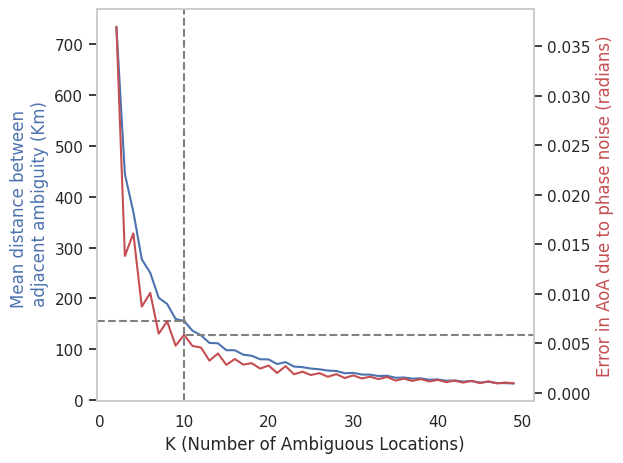

In [33]:
fig = plt.figure()
fig, ax1 = plt.subplots()
ax2 = ax1.twinx()

c = 3e8
lam = c/11.325e9
pi = np.pi
noise = 0.1 # rad
# distance coeff K (D=K*lam/2)
K = np.arange(2, 50)
print(K)
mean_dist_perambiguity = []
mean_noise_impact_perambiguity = []
for num_ambiguity in K:
    D = num_ambiguity*lam/2
    k = np.arange(int(-num_ambiguity/2), int(num_ambiguity/2)+1)
    print("k", k)
    aoa_elevations = np.arange(70, 91, 5) # in degrees
    aoa_elevations = np.radians(aoa_elevations)
    dist_diffs_peraoa = []
    error_with_noise_peraoa = []
    for e in aoa_elevations:
        del_phi = 2*pi*D*np.cos(e)/lam
        del_phi_ = 2*pi*D*np.cos(e)/lam + noise
        angles = np.arccos(del_phi*lam/(2*pi*D) + k*lam/D)
        angle_with_noise = np.arccos(del_phi_*lam/(2*pi*D) + k*lam/D)
        error_with_noise = np.abs(angles - angle_with_noise)
        error_with_noise = error_with_noise[~np.isnan(error_with_noise)]
        error_with_noise_peraoa.append(np.mean(error_with_noise))
        diff_angles = np.diff(angles)
        # remove if nan values exist
        diff_angles = diff_angles[~np.isnan(diff_angles)]
        dist_diffs = diff_angles*600
        mean_dist_diff = np.mean(dist_diffs)
        dist_diffs_peraoa.append(mean_dist_diff)
        print("dist_diffs", dist_diffs, "mean", mean_dist_diff)
    mean_dist_perambiguity.append(np.mean(dist_diffs_peraoa))
    mean_noise_impact_perambiguity.append(np.mean(error_with_noise_peraoa))
mean_dist_perambiguity = np.abs(mean_dist_perambiguity)
mean_noise_impact_perambiguity = np.array(mean_noise_impact_perambiguity)
# plt.figure()
ax1.plot(K, mean_dist_perambiguity)
ax1.set_xlabel('K (Number of Ambiguous Locations)', fontsize=12)
ax1.set_ylabel('Mean distance between \n adjacent ambiguity (Km)', color='b', fontsize=12)
ax2.set_ylabel('Error in AoA due to phase noise (radians)', color='r', fontsize=12)
ax2.plot(K, mean_noise_impact_perambiguity, 'r')
# draw 
# invert y axis for ax2
# ax2.invert_yaxis()
# turn off grid for ax2 and ax1
ax1.grid(False)
ax2.grid(False)
# draw verical line at K=10
ax1.axvline(x=10, color='grey', linestyle='dashed')
# draw horizontal line to ax2 where K=10
ax2.axhline(y=mean_noise_impact_perambiguity[8], xmin=10/49, color='grey', linestyle='dashed')
# draw horizontal line to ax1 where K=10
ax1.axhline(y=mean_dist_perambiguity[8], xmax=10/49, color='grey', linestyle='dashed')
# save with high DPI
# save figure with both axes
figure = plt.gcf()
figure.tight_layout()
plt.savefig('ambiguity_res_tradeoff.pdf')
plt.show()

### Plot coarse location error

Text(0, 0.5, 'Coarse Location Error (Km)')

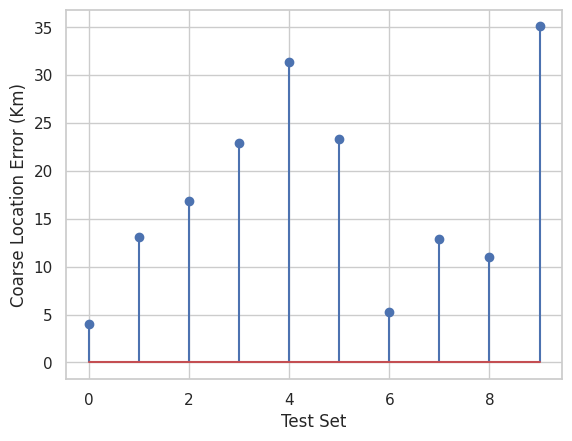

In [28]:
# plotting coarse gs error
coarse_gs_err = [res_dict[dir]['coarse_loc_err'] for dir in res_dirs]
coarse_gs_err = np.array(coarse_gs_err)
coarse_gs_err = np.sort(coarse_gs_err)
plt.stem(coarse_gs_err)
plt.xlabel('Test Set')
plt.ylabel('Coarse Location Error (Km)')

In [40]:
for dir in res_dirs:
    print(dir, res_dict[dir]['gt'], res_dict[dir]['loc_coords'], res_dict[dir]['phase_err_overall'])

13Mar2024_03_59 [ 40.11142412 -88.16207355] [40.10555569637516, -88.18155173082116] 1782.3264171827332
13Mar2024_03_17 [ 40.11183436 -88.20519719] [40.106868767459765, -88.2282169914408] 2036.2612652617888
12Mar2024_23_35 [ 40.10738645 -88.28293988] [40.11054637278699, -88.30831902997882] 2189.2483327429113
13Mar2024_02_20 [ 40.14188631 -88.22031649] [40.155880247926135, -88.19492445580234] 2663.790609185643
13Mar2024_00_54 [ 40.10243797 -88.33240108] [40.10740355922349, -88.3270895552549] 714.2045428920565
13Mar2024_00_35 [ 40.1024458  -88.33238779] [40.10741138727757, -88.33533863589481] 607.1882398791253
12Mar2024_23_17 [ 40.10738315 -88.28293573] [40.082555191795805, -88.29060849457768] 2839.9741006924196
13Mar2024_05_37 [ 40.10096119 -88.23833465] [40.10953812212754, -88.25072794460576] 1423.0957043724923
20Feb2024_23_19 [ 40.07214864 -88.20947974] [40.05544619954881, -88.22422741663277] 2243.9310112327744
6Mar2024_03_51 [ 40.11614837 -88.22277704] [40.14278198783926, -88.19621404

In [30]:
# print mean of overall
phase_err_overall = np.array([res_dict[dir]['phase_err_overall'] for dir in res_dict], dtype=np.float64)
dopp_baseline_overall = np.array([res_dict[dir]['dopp_baseline_overall'] for dir in res_dict], dtype=np.float64)
print('phase_err_overall', np.mean(phase_err_overall), np.std(phase_err_overall))
print('dopp_baseline_overall', np.mean(dopp_baseline_overall), np.std(dopp_baseline_overall))


phase_err_overall 2017.670364157456 863.5329037800615
dopp_baseline_overall 3454.91785504217 1133.967885161968


Effect of orientation errors from simulations

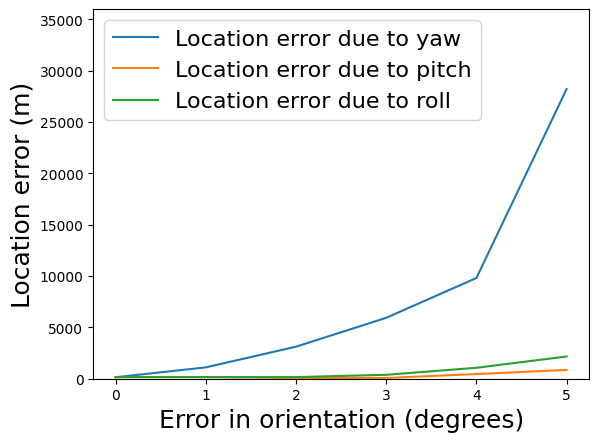

In [13]:
### Plot errors due to orientation
import csv
from tkinter import font

from requests import head
# read orientation errors from csv
yaw_errs = []
pitch_errs = []
roll_errs = []
degree_err = []
with open('/home/ishani/LeoPNT/orientation_errors.csv', newline='') as csvfile:
    reader = csv.reader(csvfile)
    header = next(reader)
    for row in reader:
        degree_err.append(float(row[0]))
        yaw_errs.append(float(row[1]))
        pitch_errs.append(float(row[2]))
        roll_errs.append(float(row[3]))
        
import matplotlib.pyplot as plt
plt.plot(degree_err[0:6], yaw_errs[0:6], label='Location error due to yaw')
plt.plot(degree_err[0:6], pitch_errs[0:6], label='Location error due to pitch')
plt.plot(degree_err[0:6], roll_errs[0:6], label='Location error due to roll')
plt.xlabel('Error in orientation (degrees)', fontsize=18)
plt.ylabel('Location error (m)', fontsize=18)
plt.legend(fontsize=16)
plt.ylim([0, 36000])
plt.savefig('/home/ishani/LeoPNT/starlink_ofdm/Starloc/results/orientation_error.pdf')

Effect of calibration on AoA

6Mar2024_04_19
13Mar2024_03_59
13Mar2024_03_17
13Mar2024_02_20
13Mar2024_00_54
13Mar2024_00_35
12Mar2024_23_17
13Mar2024_05_37
6Mar2024_03_51
[ 1.49993446  1.55042179  1.60937137  1.86754143  2.01044766  2.10023634
  2.88278707  2.89295531  2.96378506  3.18322002  3.20200079  3.58805274
  3.77091007  3.91005098  4.04589806  4.24090717  4.92262279  4.98882417
  5.60547237  7.20245962  7.44748243  8.11133487  8.61217028  8.65900181
  9.55601183 10.55286834 10.78755237 14.01270174 14.34800009 14.85195292
 15.66248247 33.56696203]
[ 1.19667942  1.38889348  1.32432203  1.43464236  1.52390875  1.69675664
  2.39493763  2.65296048  2.07531773  2.55568084  2.48191337  3.08437826
  3.83802279  3.2663905   3.22502047  3.33131889  4.06539588  4.79466176
  3.28396158  5.10794274 10.51982367  1.9728562   8.5366499   1.50494205
 12.10881223  4.92372994 17.33446208  9.68795758 20.57106685 20.0352499
 25.64732692 42.15736742]


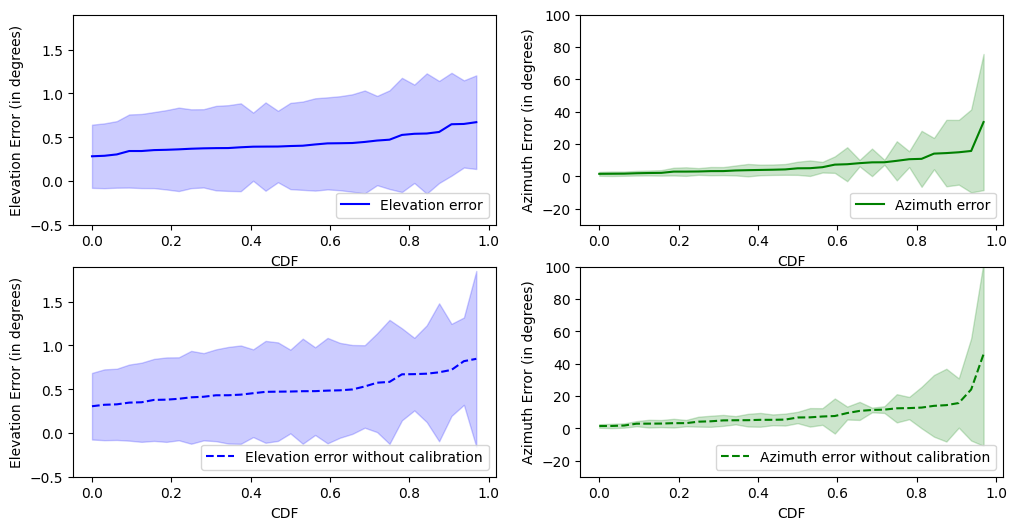

In [100]:
from turtle import color
import scipy.io as sio
import numpy as np
import os

res_dir = '/home/ishani/LeoPNT/starlink_ofdm/Starloc/results/final/'
err_az_all = []
err_az_std_all = []
err_el_all = []
err_el_std_all = []
err_az_wo_calib_all = []
err_az_wo_calib_std_all = []
err_el_wo_calib_all = []
err_el_wo_calib_std_all = []

for dir in os.listdir(res_dir):
    # check if aoa.mat exists
    if not os.path.exists(os.path.join(res_dir, dir, 'aoa_2.mat')):
        continue
    else:
        print(dir)
        # read the mat file and get the error in elevation and azimuth
        data = sio.loadmat(os.path.join(res_dir, dir, 'aoa_2.mat'))
        
        # get err_az and make it a list
        err_az_all.extend(data['err_az'][:,0].flatten())
        err_az_std_all.extend(data['err_az'][:,1].flatten())
        err_el_all.extend(data['err_el'][:,0].flatten())
        err_el_std_all.extend(data['err_el'][:,1].flatten())
        err_az_wo_calib_all.extend(data['err_az_wo_cali'][:,0].flatten())
        err_az_wo_calib_std_all.extend(data['err_az_wo_cali'][:,1].flatten())
        err_el_wo_calib_all.extend(data['err_el_wo_cali'][:,0].flatten())
        err_el_wo_calib_std_all.extend(data['err_el_wo_cali'][:,1].flatten())

err_az_all = np.array(err_az_all)
err_az_std_all = np.array(err_az_std_all)
err_el_all = np.array(err_el_all)
err_el_std_all = np.array(err_el_std_all)
err_az_wo_calib_all = np.array(err_az_wo_calib_all)
err_az_wo_calib_std_all = np.array(err_az_wo_calib_std_all)
err_el_wo_calib_all = np.array(err_el_wo_calib_all)
err_el_wo_calib_std_all = np.array(err_el_wo_calib_std_all)

# plot cdf of errors with std as shaded region

err_az_std_all = err_az_std_all[np.argsort(err_az_all)]
err_az_all = np.sort(err_az_all)
err_el_std_all = err_el_std_all[np.argsort(err_el_all)]
err_el_all = np.sort(err_el_all)
err_az_wo_calib_std_all = err_az_wo_calib_std_all[np.argsort(err_az_wo_calib_all)]
err_az_wo_calib_all = np.sort(err_az_wo_calib_all)
err_el_wo_calib_std_all = err_el_wo_calib_std_all[np.argsort(err_el_wo_calib_all)]
err_el_wo_calib_all = np.sort(err_el_wo_calib_all)

yvals = np.arange(len(err_az_all))/float(len(err_az_all))
print(err_az_all)
print(err_az_std_all)

# # plot cdf of errors
# err_az_all = np.sort(err_az_all)
# err_el_all = np.sort(err_el_all)
# err_az_wo_calib_all = np.sort(err_az_wo_calib_all)
# err_el_wo_calib_all = np.sort(err_el_wo_calib_all)
# yvals = np.arange(len(err_az_all))/float(len(err_az_all))
plt.figure(figsize=(12, 6))
plt.subplot(2, 2, 1)
plt.plot(yvals, err_el_all, label='Elevation error', color='b')
plt.fill_between(yvals, err_el_all-err_el_std_all, err_el_all+err_el_std_all, color='b', alpha=0.2)
plt.ylim([-0.5, 1.9])
plt.xlabel('CDF')
plt.ylabel('Elevation Error (in degrees)')
plt.legend(loc='lower right')
plt.subplot(2, 2, 2)
plt.plot(yvals, err_az_all, label='Azimuth error', color='g')
plt.fill_between(yvals, err_az_all-err_az_std_all, err_az_all+err_az_std_all, color='g', alpha=0.2)
plt.ylim([-30, 100])
plt.xlabel('CDF')
plt.ylabel('Azimuth Error (in degrees)')
plt.legend(loc='lower right')
plt.subplot(2, 2, 3)
plt.plot(yvals, err_el_wo_calib_all, label='Elevation error without calibration', color='b', linestyle='dashed')
plt.fill_between(yvals, err_el_wo_calib_all-err_el_wo_calib_std_all, err_el_wo_calib_all+err_el_wo_calib_std_all, color='b', alpha=0.2)
plt.ylim([-0.5, 1.9])
plt.xlabel('CDF')
plt.ylabel('Elevation Error (in degrees)')
plt.legend(loc='lower right')
plt.subplot(2, 2, 4)
plt.plot(yvals, err_az_wo_calib_all, label='Azimuth error without calibration', color='g', linestyle='dashed')
plt.fill_between(yvals, err_az_wo_calib_all-err_az_wo_calib_std_all, err_az_wo_calib_all+err_az_wo_calib_std_all, color='g', alpha=0.2)
plt.ylim([-30, 100])
plt.xlabel('CDF')
plt.ylabel('Azimuth Error (in degrees)')
plt.legend(loc='lower right')
plt.show()

# # plt.plot(err_el_wo_calib_all, yvals, label='Elevation error without calibration', color='b', linestyle='dashed')
# # plt.legend(loc='lower right')
# # plt.xlabel('Error (degrees)')
# # plt.ylabel('CDF')
# # plt.subplot(1, 2, 2)
# # plt.plot(err_az_all, yvals, label='Azimuth error', color='g')
# # plt.plot(err_az_wo_calib_all, yvals, label='Azimuth error without calibration', color='g', linestyle='dashed')
# # plt.legend(loc='lower right')
# # plt.xlabel('Error (degrees)')
# # plt.ylabel('CDF')


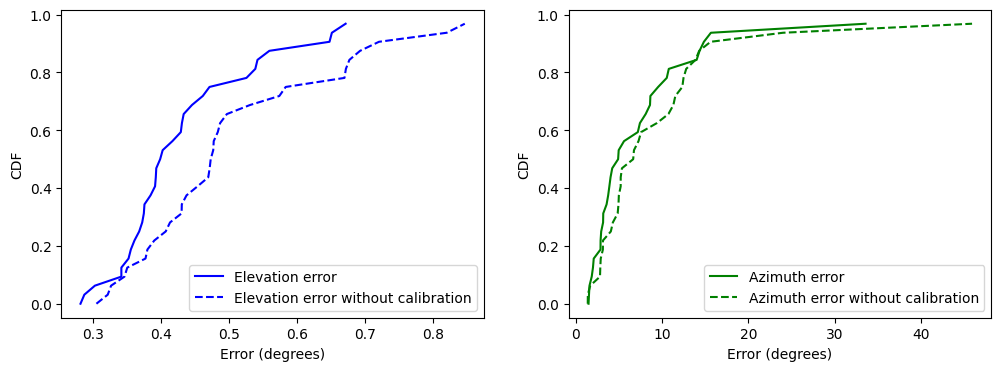

In [102]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(err_el_all, yvals, label='Elevation error', color='b')
plt.plot(err_el_wo_calib_all, yvals, label='Elevation error without calibration', color='b', linestyle='dashed')
plt.legend(loc='lower right')
plt.xlabel('Error (degrees)')
plt.ylabel('CDF')
plt.subplot(1, 2, 2)
plt.plot(err_az_all, yvals, label='Azimuth error', color='g')
plt.plot(err_az_wo_calib_all, yvals, label='Azimuth error without calibration', color='g', linestyle='dashed')
plt.legend(loc='lower right')
plt.xlabel('Error (degrees)')
plt.ylabel('CDF')
# plt.show()
# save with high DPI
plt.savefig('/home/ishani/LeoPNT/starlink_ofdm/Starloc/results/effect_of_calib_aoa_errors.pdf')


Effect of timing offset

In [11]:
import csv

err_csv = '/home/ishani/LeoPNT/sat_position_timing_err_eachsat.csv'
err_arr = []
t = np.arange(0, 2, 0.2)
t_ = []
with open(err_csv,'r') as csvfile:
    reader = csv.reader(csvfile)
    header = next(reader)
    # read every 10 lines
    idx = 0
    for row in reader:
        if row[1] == '':
            continue
    
        err_arr.append(float(row[1]))
        idx += 1
# plt.plot(t_, err_arr)
print(err_arr)    

[70.8287259953147, 158.377846085227, 158.377846085227, 255.376603351893, 255.376603351893, 1062.43088992971, 887.481392988448, 1108.6449225966, 887.481392988448, 1052.94470993132, 2004.59059394219, 2004.59059394219, 2154.17160276527, 1933.24798653944, 2092.74615183067, 3025.80450090014, 3048.92779737384, 3171.51389629133, 2979.01950409944, 3199.85966844006, 4069.41697477901, 4069.41697477901, 4217.13544608098, 4093.99839419415, 4245.58987362726, 5090.31423596871, 5113.91249684226, 5236.05878010756, 5139.35500462049, 5291.33723421323, 6134.356519173, 6134.356519173, 6281.43389453615, 6158.84180750629, 6308.52977677079, 7178.90281738949, 7178.90281738949, 7300.85796516523, 7300.85796516523, 7450.49520065674, 8102.07564490544, 8296.64126709006, 8346.07671284331, 8320.79281011559, 8468.99523959167, 9146.78339212152, 9341.07111928239, 9365.74326098545, 9365.74326098545, 9514.541688874]


[[  70.828726    158.37784609  158.37784609  255.37660335  255.37660335]
 [1062.43088993  887.48139299 1108.6449226   887.48139299 1052.94470993]
 [2004.59059394 2004.59059394 2154.17160277 1933.24798654 2092.74615183]
 [3025.8045009  3048.92779737 3171.51389629 2979.0195041  3199.85966844]
 [4069.41697478 4069.41697478 4217.13544608 4093.99839419 4245.58987363]
 [5090.31423597 5113.91249684 5236.05878011 5139.35500462 5291.33723421]
 [6134.35651917 6134.35651917 6281.43389454 6158.84180751 6308.52977677]
 [7178.90281739 7178.90281739 7300.85796517 7300.85796517 7450.49520066]
 [8102.07564491 8296.64126709 8346.07671284 8320.79281012 8468.99523959]
 [9146.78339212 9341.07111928 9365.74326099 9365.74326099 9514.54168887]]
(10, 5)


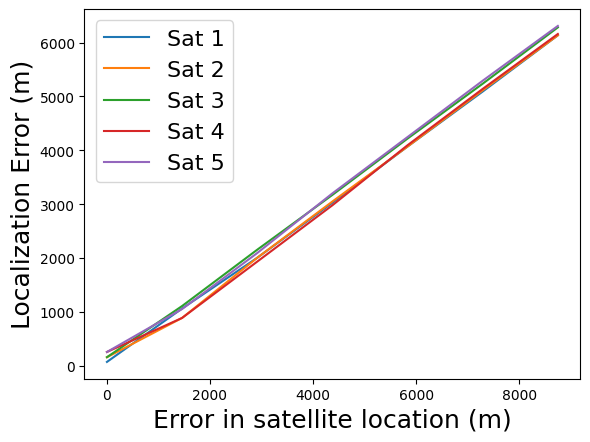

In [14]:
import numpy as np
err_arr = np.array(err_arr)
print(err_arr)
# reshape to -1,5
err_arr = err_arr.reshape(-1, 5)
print(err_arr.shape)
dist_offset = [ 0 ,
    1458.6799480588963, 2917.3676488700394, 4376.04120572976, 5834.722482768778,
    7293.404170231844, 8752.086251820454, 10210.77600474083, 11669.451532233677,
    13128.134698482134
]
for i in range(5):
    plt.plot(dist_offset[0:7], err_arr[0:7,i], label='Sat '+str(i+1))
plt.xlabel('Error in satellite location (m)', fontsize=18)
plt.ylabel('Localization Error (m)', fontsize = 18)
plt.legend(fontsize=16)
plt.savefig('/home/ishani/LeoPNT/starlink_ofdm/Starloc/results/loc err_vs_sat_pos_err.pdf')
plt.show()